# 1.1 · Building the research database from scratch

This notebook takes an **empty database** and loads everything the research needs, for two markets: the daily
constituents of the S&P 500, 400 and 600 and of London's FTSE 100, 250 and SmallCap since 2005, unadjusted daily
prices with the corporate actions needed to adjust them, company financial statements dated by when they became
public, analysts' estimates, and the benchmark indices strategies are measured against. (The words of annual reports
are loaded apart, by notebook 1.3.)

* **Run time:** two to three days. The binding constraint is LSEG (formerly Refinitiv), which allows 10,000 API
  requests per user per day, reset at local midnight. A full build needs about 15,000: about 7,500 for the US prices
  and statements, about 3,200 for the US analysts' estimates, about 4,000 for London, and London's estimates on top.
  The estimates are also slow (a few hundred requests an hour: each returns years of monthly history). When the
  allowance runs out the load stops cleanly; rerun the notebook after midnight and it resumes where it stopped.
* **Idempotent:** every step writes only what is missing, so a second run finds nothing new and writes nothing.
* **Prerequisites:** each vendor needs something on this machine - LSEG Workspace running and signed in, a contact
  name for the SEC's API (it requires one in the User-Agent header), and API keys for Tiingo or SimFin if you use them
  (Step 3 lists them). Settings and keys are stored in the operating system's credential store (the *keyring*), never
  in code or files: `uv run eqr set-key simfin` stores a key without echoing it. To build a local database instead of
  the shared Azure one, set `EQR_DB_SERVER` and `EQR_DB_NAME` before starting Jupyter (see
  `src/equity_research/settings.py`).

## Architecture in brief

The data moves through four stages:

```
  vendors      ──►  raw zone          ──►  canonical database   ──►  research cache     ──►  research
  (LSEG, SEC,       (every response,       (normalised tables,       (local Parquet         (backtests,
   Yahoo, ...)       stored as received)    shared, SQL Server)       copy, DuckDB)          screens)
```

1. **Raw zone** (`data/<database>/raw`). Every vendor response is written to disk, unchanged, before anything else
   is done with it. If a parsing bug is found later, the same responses are normalised again; nothing has to be
   downloaded twice, and every stored number can be traced back to the response it came from.
2. **Canonical database.** Responses are normalised into one set of tables that does not depend on the vendor. Several
   users can share it.
3. **Research cache.** Each user keeps a local columnar copy, so experiments are fast and put no load on the server.

Three design rules keep the data fit for backtesting:

* **Store primitives, derive the rest.** We store the traded (unadjusted) price each day plus splits and dividends,
  not vendor-adjusted prices. Adjusted prices, returns and ratios are computed on demand, the same way for every
  vendor, so a change in one vendor's adjustment method cannot silently change the research.
* **Point-in-time data (two clocks).** Every financial figure carries the date of the period it describes (*period
  end*) and the date it first became public (*published*). A backtest may use a figure only after it was published.
  Using it earlier is *look-ahead bias*: the simulation trades on information no investor had, which inflates
  returns.
* **Vendor independence.** Each vendor is reached through its own adapter
  (`src/equity_research/ingest/vendors/<vendor>`) and appears in the database only as a small integer: 1 = LSEG,
  2 = SEC, 3 = Yahoo, 4 = FinanceDatabase, 5 = Norgate, 6 = Tiingo, 7 = SimFin, and 8 = SRAF, the home of the
  word list notebook 1.3 uses (`ref.vendor`). Replacing a vendor means writing one adapter (or, for the first seven,
  changing a setting), not rewriting the research.

## What we store, and why

| # | Data | Table | Source | Contents | Why it is needed |
|---|---|---|---|---|---|
| 1 | **Vendors** | `ref.vendor` | us | The data vendors, each with an integer id | Every other row records which vendor supplied it |
| 2 | **Issuers** | `ref.issuer`, `ref.classification` | LSEG, SEC (Norgate; sectors also FinanceDatabase, SimFin) | One row per company (Alphabet, Apple...) with its country of domicile; its GICS sector, with the dates each classification applied | Financial statements and sectors belong to the *issuer*, and sectors change over time (Alphabet moved to Communication Services in 2018) |
| 3 | **Listings** | `ref.listing` | LSEG, Yahoo (Norgate) | One row per tradable instrument: a share class, a fund or an index. Alphabet has two (GOOG and GOOGL) | Prices belong to a *listing*. Separating issuer from listing stops Alphabet's earnings being counted twice |
| 4 | **Identifiers** | `ref.identifier` | all | Tickers, RICs (LSEG's codes), CUSIPs, ISINs, SEDOLs, the SEC's CIK, Yahoo symbols | Each vendor keys securities differently and tickers are reused or change (FB became META), so any identifier must resolve to the right listing on a given date |
| 5 | **Index constituents** | `ref.index_membership` | LSEG (Norgate) | Daily membership of the S&P 500 / 400 / 600 and the FTSE 100 / 250 / SmallCap since 2005, including companies later delisted, acquired or bankrupt | Backtesting on today's constituents only is *survivorship bias*: it tests a sample selected for having done well |
| 6 | **Universes** | `ref.universe` | us | The investable pools (S&P 1500 = 500 large + 400 mid + 600 small caps; FTSE All-Share = FTSE 100 + 250 + SmallCap) and an assumed trading cost for each | Smaller companies are more expensive to trade; the backtest charges for it |
| 7 | **Daily prices** | `market.price_bar` | LSEG, Yahoo (Norgate, Tiingo) | Open, high, low, close and volume as traded that day (unadjusted) | Returns, momentum, volatility and market capitalisation all derive from these |
| 8 | **Corporate actions** | `market.corporate_action` | LSEG, Yahoo (Norgate, Tiingo) | Cash dividends per share; splits (a 4-for-1 split turns one $400 share into four $100 shares); spin-offs | Without splits, a split appears as a 75 % one-day loss; without dividends, total return is understated |
| 9 | **Shares outstanding** | `market.share_count` | LSEG (the SEC's counts as fallback) | Monthly shares outstanding per share class, and the *free float* (shares available to the public) | Market capitalisation = price × shares outstanding; index weights use the float-adjusted figure |
| 10 | **Financial statements** | `fund.filing`, `fund.financial_fact` | SEC, LSEG (SimFin) | Revenue, earnings, debt, cash, assets..., each with the date it was published | Value and quality factors are built from these, using only what was public at the time. Two vendors allow cross-checking |
| 11 | **Benchmarks** | `market.price_bar` | Yahoo, LSEG | S&P 500 (^GSPC), S&P 400 and 600, S&P 500 Equal Weight (^SPXEW), and the ETFs SPY and RSP | The comparison for every strategy: does it beat a passive index investment? |
| 12 | **Analysts' estimates** | `fund.estimate`, `fund.estimate_revision`, `fund.estimate_actual` | LSEG (I/B/E/S) | The consensus forecast of earnings, revenue and dividends for the current and next two fiscal years as it stood at each month end since 2005; the number of analysts revising up or down; the reported actuals | Forward-looking value, growth and *estimate revision* factors (Barings' GARP, notebook 3.6). Per-share forecasts are stored on the share basis of their own date, like prices |
| 13 | **Audit trail** | `ingest.batch`, `ops.job_run`, `ops.check_result`, `research.run` | us | A record of every vendor response, every job, every data-quality check and every backtest | Provenance for every number, and a count of how many strategies were tried (needed to correct for multiple testing; notebook 3.1) |

Vendors in brackets can replace or supplement a row through a setting (Step 3); the tables and the research are unchanged.

Filing text - the SEC's index of every filing and the text measures of the annual reports (`fund.document`, `fund.text_measure`) - is loaded by notebook 1.3, after this one.

In [1]:
import logging

import pandas as pd
from IPython.display import display

from equity_research.db.engine import create_database, get_engine
from equity_research.settings import get_settings

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4g}")

# progress lines while the loads run (one per LSEG step and year, SEC every 100 companies)
logging.basicConfig(level=logging.INFO, format="%(asctime)s  %(message)s", datefmt="%H:%M:%S", force=True)
for noisy in ("httpx", "lseg", "urllib3", "alembic"):
    logging.getLogger(noisy).setLevel(logging.WARNING)

settings = get_settings()
print("Database:      ", settings.database.server, "/", settings.database.name)
print("Signed in with:", "a database login" if settings.database.uses_sql_auth else "Windows authentication")
print("Files kept in: ", settings.data_dir)

Database:       MENONPC\SQLEXPRESS / equity_research_local
Signed in with: Windows authentication
Files kept in:  C:\SourceCode\EquityResearch\data\equity_research_local


## Step 1 · Create the database and its schema

On a local SQL Server, `create_database` creates the empty database if it does not exist (an Azure database is
created once in the Azure portal, where its pricing tier is chosen).

The tables are created by **migrations** (Alembic): numbered, version-controlled scripts
(`migrations/versions/0001_...`) that create or alter the schema. Nobody alters tables by hand; each change is a new
migration, so every copy of the database ends up with an identical schema. The first migration also inserts the
vendor list.

In [2]:
from equity_research.db.inventory import newest, table_rows
from equity_research.db.migrate import upgrade_to_latest

print("Created a new database" if create_database(settings.database) else "The database already exists")
print("Shelves are at recipe", upgrade_to_latest())
engine = get_engine()
display(table_rows(engine))

The database already exists


Shelves are at recipe 0008


,schema,table,rows
0,fund,document,0
1,fund,estimate,6282877
2,fund,estimate_actual,185412
3,fund,estimate_revision,256196
4,fund,filing,127035
5,fund,financial_fact,7701276
6,fund,text_measure,0
7,ingest,batch,2164
8,market,corporate_action,101159
9,market,price_bar,10822764


## Step 2 · Smoke-test each vendor

Before a load that runs for hours, each vendor in this build is sent a few requests whose answers are known, and each
response is parsed by the same code the load uses:

* **LSEG:** one small request per data type (about a dozen requests, including one 11-year price history to confirm
  it comes back complete) and one per type of analysts' estimate (another dozen).
* **Norgate and Tiingo:** a known split and dividend.
* **SimFin:** which identifiers its company file carries.

A field a vendor has renamed or stopped serving shows up here within a minute, instead of hours into the load. Every
row should read `ok`; the last LSEG row reports how much of today's request allowance remains. Vendors that publish
bulk files (Yahoo, the SEC, FinanceDatabase) have nothing to test in advance.

In [3]:
from equity_research.pipelines.sources import probe_sources

display(probe_sources())

C:\SourceCode\EquityResearch\.venv\Lib\site-packages\lseg\data\_tools\_dataframe.py:192:FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


C:\SourceCode\EquityResearch\.venv\Lib\site-packages\lseg\data\_tools\_dataframe.py:192:FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


C:\SourceCode\EquityResearch\.venv\Lib\site-packages\lseg\data\_tools\_dataframe.py:192:FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


C:\SourceCode\EquityResearch\.venv\Lib\site-packages\lseg\data\_tools\_dataframe.py:192:FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
C:\SourceCode\EquityResearch\.venv\Lib\site-packages\lseg\data\_tools\_dataframe.py:192:FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
C:\SourceCode\EquityResearch\.venv\Lib\site-packages\lseg\data\_tools\_dataframe.py:192:FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. 

C:\SourceCode\EquityResearch\.venv\Lib\site-packages\lseg\data\_tools\_dataframe.py:192:FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


C:\SourceCode\EquityResearch\.venv\Lib\site-packages\lseg\data\_tools\_dataframe.py:192:FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
C:\SourceCode\EquityResearch\.venv\Lib\site-packages\lseg\data\_tools\_dataframe.py:192:FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
C:\SourceCode\EquityResearch\.venv\Lib\site-packages\lseg\data\_tools\_dataframe.py:192:FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. 

... (5 outputs left out)

C:\SourceCode\EquityResearch\.venv\Lib\site-packages\lseg\data\_tools\_dataframe.py:192:FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


C:\SourceCode\EquityResearch\.venv\Lib\site-packages\lseg\data\_tools\_dataframe.py:192:FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
C:\SourceCode\EquityResearch\.venv\Lib\site-packages\lseg\data\_tools\_dataframe.py:192:FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


C:\SourceCode\EquityResearch\.venv\Lib\site-packages\lseg\data\_tools\_dataframe.py:177:FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


,source,check,ok,detail
0,refinitiv,index members,True,
1,refinitiv,instruments,True,
2,refinitiv,classification,True,
3,refinitiv,domicile,True,
4,refinitiv,prices,True,
5,refinitiv,"prices, one whole window",True,
6,refinitiv,dividends,True,
7,refinitiv,capital changes,True,
8,refinitiv,share counts,True,
9,refinitiv,announcements,True,


## Step 3 · Load every source

The database is filled by an ordered list of **sources**, one per vendor. The list is defined in one place
(`vendor_preferences().sources` in `src/equity_research/settings.py`, overridable with `EQR_SOURCES`), so switching or
adding a vendor means one new adapter plus one entry in that list; this notebook does not change.

The table below lists every vendor the code supports: what it supplies, what it needs on this machine, and whether
this build uses it. To build without LSEG, for example, set before starting Jupyter:

```
EQR_SOURCES=norgate,yahoo,financedatabase,sec   EQR_PRICE_VENDORS=norgate   EQR_MEMBER_VENDORS=norgate
```

Order matters: the first vendor creates the listings and the later ones attach their identifiers and prices to them
(Tiingo and SimFin never create listings; they only supplement existing ones).

The default sources:

**1. LSEG (Refinitiv)** - six request types, in order, each depending on the previous one:

* **Universe.** Today's constituents of the S&P 500, 400 and 600 and every addition and deletion since 2005. LSEG
  cannot return the constituents on a past date directly, so historical membership is reconstructed by starting from
  today's list and *replaying additions and deletions backwards*. A member whose addition LSEG did not record is never
  counted before its first trading day. Then each listing's identifiers (ISIN, CUSIP, ticker, every RIC it ever had),
  its issuer, the issuer's sector and its country of domicile.
* **Prices.** Close and volume on every trading day, from a year before a listing joined an index (12-month momentum
  needs a year of history) until it left, plus the index levels. LSEG charges **one request per listing** for a price
  history and returns at most about 3,000 days per request, so each listing is requested once per 11-year window
  (2003-2013, 2014-2024, 2025 on) - about 6,500 requests in total.
* **Dividends, splits and spin-offs.** LSEG's split dates are occasionally off by a day, so each split is validated
  against the price series: on the true ex-date the price falls by the split ratio.
* **Shares outstanding.** Monthly, per share class, and the free float.
* **Quarterly statements.** LSEG's quarterly figures, converted to US dollars, with each quarter's announcement date.
* **Annual statement items.** Items LSEG serves only per fiscal year and only one field per request: cash flows,
  depreciation, inventories, dividends paid, unusual items and, for banks, net interest income, loan-loss
  provisions, loans and deposits (~150 requests). Share issuance, buybacks, debt flows and regulatory capital ratios
  come from the SEC only: LSEG has no history for the first three, and its capital ratios are broker estimates, which
  are never stored as reported figures.

Each request is stored with a description of exactly what was asked. Before each request the load checks the
remaining allowance and stops before exhausting it; the report then says so. **Rerun this cell the next day**: it
re-reads what was already received and requests only the remainder.

**2. LSEG analysts' estimates (I/B/E/S).** The consensus as it stood at every month end since 2005, for every company
ever in our indices: earnings, revenue and EBIT (operating profit) for the current fiscal year and the next two,
dividends and cash flow per share, and return on equity. Each comes with the mean, median, standard deviation and
number of contributing analysts. Also stored: each year's reported actual and its announcement date, and, for that
date's index members, how many analysts raised or lowered their earnings estimate. About 3,200 requests (most
of a day: a few hundred an hour, each returning years of monthly history), so the first day usually ends at LSEG's
limit and the load continues the next.

Two LSEG behaviours are corrected for:

* **Split restatement.** LSEG restates historical per-share estimates to *today's* share basis (Apple's 2015 forecast
  comes back divided by its 2020 split). The load converts each figure back to the share basis of its own date using
  the stored splits, so a later split never changes a stored value and the data stays point-in-time.
* **Revision counts.** LSEG serves revision counts only one date per request; requested as a time series, it never
  responds and the client library retries indefinitely, each retry costing a request. The load therefore asks month
  by month, and the LSEG client aborts any call that keeps consuming requests without returning an answer.

**3. London (LSEG).** The same steps for the FTSE 100, 250 and SmallCap - together the FTSE All-Share - and then
their analysts' estimates, with what differs in London:

* **Prices are quoted in pence**, and the day's price is the exchange's official close; dividends are in pounds.
* **Companies report half-yearly.** Their statements are stored as first reported, in pounds.
* **Investment trusts** - funds listed as companies - are members of these indices and are loaded; research leaves
  them out of a universe, since their accounts are a portfolio's, not a business's.
* **Stamp duty.** Buying a London share costs 0.5 % in tax where the company is incorporated in the UK (1 % in
  Ireland); the backtest charges it on purchases, apart from the trading cost.
* The index levels, and the All-Share's level with dividends (the universe's benchmark), come from LSEG too.

About 4,000 requests, and London's estimates on top - the second and third day of a build.

**4. Yahoo Finance.** Free and current, so it supplies the US benchmarks:

| Symbol | Description |
|---|---|
| `^GSPC` | The S&P 500 price index - excludes dividends |
| `SPY` | An ETF tracking the S&P 500. Its price plus its dividends gives the investor's total return |
| `^SPXEW` | The S&P 500 *Equal Weight* index - every constituent has the same weight |
| `RSP` | An ETF tracking the equal-weight S&P 500 |
| `SPTM` | An ETF tracking the S&P Composite 1500 (500 + 400 + 600), market-cap weighted |
| `^SP400`, `^SP600` | The mid-cap and small-cap indices |

Where LSEG already supplies an index under its own code (the S&P 500 is `.SPX` at LSEG), Yahoo's prices are attached
to the **same listing**: one index, two vendors.

**5. The SEC.** US-listed companies must file their financial statements with the SEC in a machine-readable format,
**XBRL**, in which each figure is tagged with a standard accounting concept (`Revenues`, `NetIncomeLoss`, ...). The
SEC publishes all of them free in one bulk file (about 1.3 GB). We download it when our copy is over a week old and
match our issuers to the SEC's company identifiers (CIK) by ticker, then CUSIP, then registrant name. A company that
re-registered (Disney became a new holding company with a new CIK in 2019) keeps both CIKs, so its earlier filings are
not lost. For each figure we keep the **first reported value** plus every later restatement, each with its
publication date. A backtest dated 2015 sees what was known in 2015, not the restated figure published in 2017.

The SEC's XBRL data only begins in 2009-2011, so research reads each company's statements from the SEC and, for the
years before its XBRL data begins, from LSEG's quarterly and annual items. LSEG keeps only its latest restated values,
so in those early years a later restatement can appear slightly before it was published - a known, limited
look-ahead.

**6. FinanceDatabase.** A free, open-source security master: it adds identifiers (ISIN, FIGI, Yahoo symbols), country
of domicile where no other vendor gave one, and its own sector labels. It only supplements existing records.

In [4]:
from equity_research.pipelines.refresh import written
from equity_research.pipelines.sources import describe_sources, run_sources

display(describe_sources())
reports = run_sources(engine, "build")
for name, report in reports.items():
    if "complete" in report:  # a source that can stop part way (LSEG's daily allowance)
        print(f"{name}: finished {report['complete']} | {report['stopped'] or 'nothing left to ask'}")
    if "lseg_requests" in report:
        print(f"{name}: {report['lseg_requests']:,} LSEG requests used; {report['allowance_left']} left today")
display(written(reports))

,source,supplies,needs,in this build
0,refinitiv,"index members, listings and codes, sectors, da...",LSEG Workspace running and signed in; up to 10...,True
1,estimates,analysts' estimates (I/B/E/S): monthly consens...,LSEG Workspace running; after refinitiv (its l...,True
2,refinitiv_uk,"London (FTSE 100 / 250 / SmallCap): members, l...","LSEG Workspace running; ~4,000 requests from n...",True
3,estimates_uk,analysts' estimates (I/B/E/S) of London's list...,LSEG Workspace running; after refinitiv_uk (it...,True
4,yahoo,"benchmark index levels and funds (^GSPC, SPY, ...",nothing (public files),True
5,financedatabase,"codes (ISIN, FIGI, Yahoo symbol), the country ...",nothing (public files),True
6,sec,"company accounts as first reported, with every...",a contact for the SEC (EQR_SEC_USER_AGENT or k...,True
7,norgate,"index members with history, listings incl. del...",Norgate Data Updater running with a subscripti...,False
8,simfin,"company accounts, standardised (dated by first...",an API key (`eqr set-key simfin`); run after s...,False
9,tiingo,"unadjusted daily prices, dividends and splits ...",an API key (`eqr set-key tiingo`); a free acco...,False


00:17:56  LSEG universe: {'requests': 6, 'reused': 60, 'domiciles': {'inserted': 0, 'updated': 0}, 'memberships': {'inserted': 0, 'updated': 0}, 'codes_left_out': [], 'listings': 3251, 'listings_created': 0, 'issuers_created': 0, 'listings_merged': 0, 'classifications': {'opened': 1, 'closed': 1}, 'identifier_conflicts': 0, 'memberships_moved_by_events': 3, 'membership_days_by_priority': 2415, 'memberships_clipped': 12, 'memberships_deleted': 0}


C:\SourceCode\EquityResearch\.venv\Lib\site-packages\lseg\data\_tools\_dataframe.py:177:FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


00:18:08  LSEG prices 2003-11-28..2013-12-31: 2348 listings, 26 RICs asked


C:\SourceCode\EquityResearch\.venv\Lib\site-packages\lseg\data\_tools\_dataframe.py:177:FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


00:18:21  LSEG prices 2014-01-01..2024-12-31: 2445 listings, 18 RICs asked


... (2,854 outputs left out)

10:22:05  SEC facts: 3000 / 3037 companies, 0 facts


10:22:13  SEC facts: 3037 / 3037 companies, 0 facts


refinitiv: finished True | nothing left to ask
refinitiv: 1,059 LSEG requests used; 8888 left today
estimates: finished True | nothing left to ask
estimates: 486 LSEG requests used; 8001 left today
refinitiv_uk: finished True | nothing left to ask
refinitiv_uk: 3,035 LSEG requests used; 4966 left today
estimates_uk: finished True | nothing left to ask
estimates_uk: 928 LSEG requests used; 3333 left today


,step,what,inserted,updated
0,refinitiv,universe / domiciles,0,0
1,refinitiv,universe / memberships,0,0
2,refinitiv,prices / price_bars,0,0
3,refinitiv,universe_after_prices / domiciles,0,0
4,refinitiv,universe_after_prices / memberships,0,20
5,refinitiv,actions / corporate_actions,17,25
6,refinitiv,shares / share_counts,0,596
7,refinitiv,actions_after_shares / corporate_actions,0,0
8,refinitiv,statements / financial_facts,303,0
9,refinitiv,annuals / financial_facts,171,0


## Step 4 · Data-quality checks

Before the data is used for research, a set of checks measures its completeness and consistency. Each check has a
*warn* threshold (investigate) and a *fail* threshold (stop: something is broken).

| Check | What it measures |
|---|---|
| `member_day_price_coverage` | Share of index member-days for which we have a price |
| `benchmark_day_coverage` | Whether every benchmark has a level on every trading day |
| `equity_listings_without_issuer` | Equity listings not linked to an issuer |
| `issuers_with_cik_without_facts` | Issuers matched to a CIK but with no SEC filings (foreign private issuers often file differently) |
| `unexplained_price_jumps` | Days on which a price moved by a factor of 2.5 or more with no split to explain it (usually a missed split) |
| `members_after_last_price` | Index memberships that continue after the listing's last price (usually a deletion the vendor missed) |
| `overlapping_membership_spells` | Any listing counted twice in one index on the same day (must be zero) |
| `members_of_two_indices` | Listings counted in two of a market's indices at once (the S&P 500 and the MidCap 400, say: they never share a member) |
| `members_before_first_trade` | Memberships that start before the listing first traded (an addition the vendor missed) |
| `facts_published_before_period_end` | Figures published before the end of the period they describe (must be zero) |
| `bars_outside_their_range` | Days whose close lies outside that day's high-low range |
| `rows_without_provenance` | Rows that cannot be traced to the vendor response they came from |
| `annual_reports_without_text_measures` | Annual reports landed by notebook 1.3 whose text was never measured (0 until that notebook has run) |

While the LSEG load is incomplete, price coverage will look poor: the check is reporting the gap correctly.

In [5]:
from equity_research.quality.checks import CORE_CHECKS, run_checks

checks = run_checks(engine, CORE_CHECKS)
display(pd.DataFrame([{"check": r.name, "status": r.status, "value": r.value, "levels": r.threshold} for r in checks]))

,check,status,value,levels
0,member_day_price_coverage,pass,0.9992,"warn >= 0.999, fail >= 0.99"
1,benchmark_day_coverage,pass,1,"warn >= 0.999, fail >= 0.5"
2,unexplained_price_jumps,warn,249,"warn <= 0, fail <= 1000000000.0"
3,members_after_last_price,warn,21,"warn <= 0, fail <= 1000000000.0"
4,equity_listings_without_issuer,pass,0,"warn <= 0, fail <= 1000000000.0"
5,facts_published_before_period_end,pass,0,"warn <= 0, fail <= 0"
6,overlapping_membership_spells,pass,0,"warn <= 0, fail <= 0"
7,members_of_two_indices,pass,0,"warn <= 0, fail <= 1000000000.0"
8,members_before_first_trade,pass,0,"warn <= 0, fail <= 1000000000.0"
9,bars_outside_their_range,pass,0,"warn <= 0, fail <= 1000000000.0"


## Step 4b · Architecture audit

The quality checks ask whether anything is missing. The **audit** checks the slower invariants of the design
(`docs/ARCHITECTURE.md`): one listing per share line, no identifier held by two issuers at the same time, coherent
membership spells, every figure dated after its period ended, every row traceable to its source response. It also
checks **fitness for research**, year by year: do each index's members have prices, statements and share counts that
were known at the time; does every benchmark cover the whole period; does every selected vendor actually supply its
data? Rows marked `False` are listed first, each with a description of what was found.

In [6]:
from equity_research.quality.audit import audit

findings = audit(engine)
print(f"{int((~findings['ok']).sum())} of {len(findings)} rules do not hold")
display(findings.sort_values("ok"))

6 of 65 rules do not hold


,area,rule,value,ok,note
35,accounts,"units are dollars, pounds or shares",3348,False,
37,accounts,"a quarter is 80-100 days, a year so far 160-29...",10691,False,
27,prices,no bars on a weekend,13,False,
25,members,"index sizes within 3% of 500 / 400 / 600, 100 ...",2,False,FTSE250 2011-06-30: 258; FTSE250 2009-06-30: 261
11,identity,no TICKER held by two entities at once,154,False,
...,...,...,...,...,...
29,prices,"prices in a currency research reads (dollars, ...",0,True,
30,prices,a listing's latest bar in the listing's currency,0,True,
31,prices,a dividend declared in another currency has it...,0,True,
16,identity,every company has a listing,0,True,


## Step 5 · Sync the local research cache

Research reads a local copy of the database (`data/<database>/cache`), stored as Parquet (a columnar file format) and
queried with DuckDB (an in-process analytical database). The sync is incremental: only rows added or changed since
the last sync are fetched.

In [7]:
from equity_research.research.cache import ResearchCache

cache = ResearchCache()
copied = cache.sync(engine)
display(pd.Series(copied, name="rows copied"))

10:28:08  cache ref.vendor: 8 rows


10:28:08  cache ref.issuer: 4519 rows


10:28:08  cache ref.classification: 6500 rows


10:28:08  cache ref.listing: 4640 rows


10:28:08  cache ref.identifier: 30137 rows


10:28:08  cache ref.index_definition: 6 rows


... (10 outputs left out)

10:29:49  cache fund.estimate_actual: 56031 rows


10:29:49  cache fund.document: 0 rows


10:29:49  cache fund.text_measure: 0 rows


ref.vendor                       8
ref.issuer                    4519
ref.classification            6500
ref.listing                   4640
ref.identifier               30137
ref.index_definition             6
ref.index_membership          7243
ref.universe                     8
ref.universe_component          12
market.price_bar           4287833
market.corporate_action      30052
market.share_count          410002
fund.filing                      0
fund.financial_fact         691936
fund.estimate              1839048
fund.estimate_revision      465872
fund.estimate_actual         56031
fund.document                    0
fund.text_measure                0
Name: rows copied, dtype: int64

## Database contents

The first table gives the row count of each table; the second gives the most recent date of each data type, per
vendor - a quick way to see whether any feed is stale.

In [8]:
display(table_rows(engine))
display(newest(engine))

,schema,table,rows
0,fund,document,0
1,fund,estimate,8121925
2,fund,estimate_actual,241443
3,fund,estimate_revision,722068
4,fund,filing,127035
5,fund,financial_fact,8393212
6,fund,text_measure,0
7,ingest,batch,4987
8,market,corporate_action,131186
9,market,price_bar,15110589


,what,vendor,newest
0,analysts' consensus,refinitiv,2026-10-31
1,company reports (published),refinitiv,2027-01-02
2,company reports (published),sec,2026-11-10
3,daily prices,refinitiv,2026-11-12
4,daily prices,yahoo,2026-11-12
5,dividends and splits,refinitiv,2027-05-20
6,dividends and splits,yahoo,2026-09-21
7,estimate revisions,refinitiv,2026-10-31
8,index membership changes,refinitiv,2026-11-11
9,raw files landed,financedatabase,2026-11-12


A sanity check on the reconstructed membership history: the number of constituents of each index at every month end.
The S&P 500 should stay close to 500 throughout, the MidCap 400 close to 400 and the SmallCap 600 close to 600.
Persistent drift or sudden jumps would indicate missing additions or deletions. (The SmallCap count runs slightly
high because LSEG's event history misses a few of its deletions.)

,FTSE100,FTSE250,FTSESC,SP400,SP500,SP600
2019-12-31,102,252,281,399,505,601
2020-12-31,102,252,261,399,505,603
2021-12-31,102,253,255,398,505,602
2022-12-31,101,253,239,399,503,603
2023-12-31,101,253,228,399,503,604
2024-12-31,101,253,211,399,503,603
2025-12-31,101,251,196,398,503,603
2026-12-31,101,251,174,399,502,600


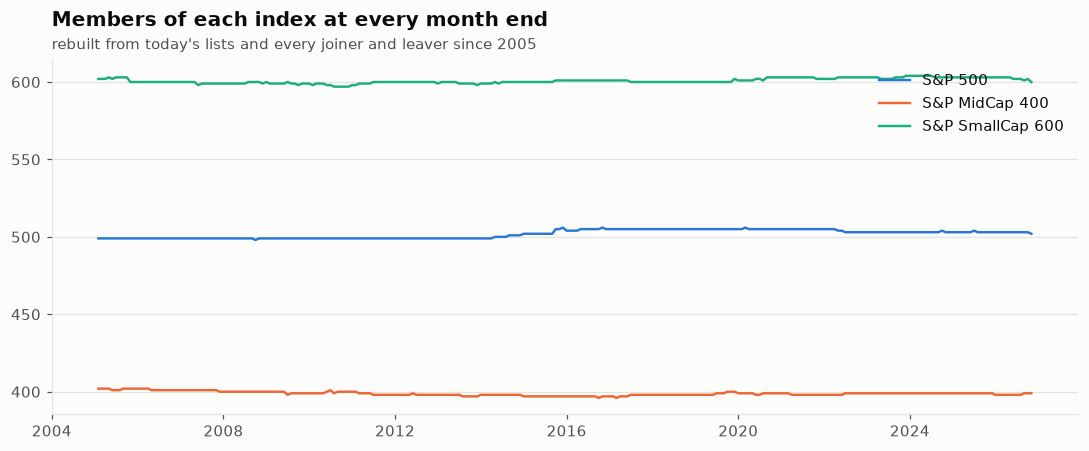

In [9]:
from equity_research import charts
from equity_research.research.data import members_over_time

charts.style()
members = members_over_time(cache)
fig = charts.lines(
    {"S&P 500": members["SP500"], "S&P MidCap 400": members["SP400"], "S&P SmallCap 600": members["SP600"]},
    "Members of each index at every month end",
    subtitle="rebuilt from today's lists and every joiner and leaver since 2005",
)
display(members.resample("YE").last().tail(8))

## Glossary

* **Listing** - a tradable instrument on an exchange: a share class, a fund or an index level.
* **Issuer** - the company behind a listing.
* **RIC** - Reuters Instrument Code, LSEG's identifier for a listing (`AAPL.OQ` is Apple on Nasdaq; `LEH.N^I08` is
  Lehman Brothers, retired in September 2008 - the `^` marks a retired code).
* **Split** - a change in the number of shares (one share becomes several, or several become one) with no change in
  the company's value; per-share figures before it must be rescaled to compare with those after.
* **Dividend** - a cash distribution to shareholders, per share; the *ex-date* is the first day the share trades
  without it.
* **Free float** - shares available to public investors, excluding those held by founders, governments and other
  strategic holders.
* **Survivorship bias** - drawing a sample only from entities that survived to the present, which overstates past
  performance.
* **Look-ahead bias** - using information in a backtest before it was actually available.
* **Point-in-time** - data stored as it was known on each date, including the first-reported value before any
  restatement.
* **Migration** - a versioned script that creates or alters database tables.
* **Raw zone** - the unmodified copies of every vendor response.

**Next:** notebook 1.2 keeps the database current with a daily incremental refresh.